# 01: NumPy bilan Gradient Descent
Maqsad: linear regression qanday o'rganishini noldan, kod orqali ko'rish.
Ma'lumot: Google ML Crash Course'dagi 7 ta mashina (og'irlik → mpg)

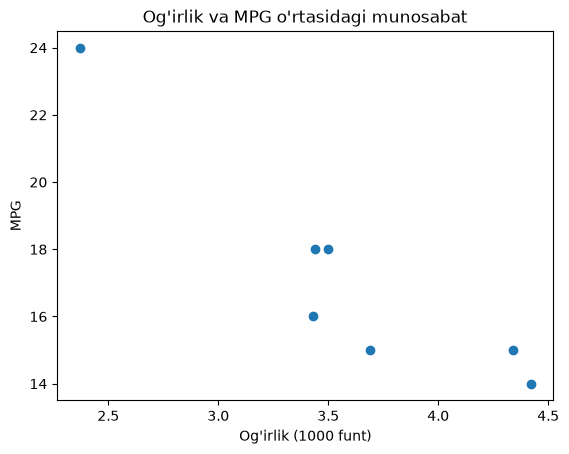

In [5]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([3.50, 3.69, 3.44, 3.43, 4.34, 4.42, 2.37])  # og'irlik (1000 funt)
y = np.array([18, 15, 18, 16, 15, 14, 24])                # mpg (label)

plt.scatter(x, y)
plt.title("Og'irlik va MPG o'rtasidagi munosabat")
plt.xlabel("Og'irlik (1000 funt)")
plt.ylabel("MPG")
plt.show()

Mashq 2: Model, Loss va Gradient funksiyalari

📖 Izoh: Butun nazariya shu 3 ta funksiyada:

predict → y’ = wx + b
mse_loss → model qanchalik xato qilyapti
gradients → w va b ni qaysi tomonga siljitish kerak

numpy bilan sikl yozish shart emas: np.mean() barcha 7 ta mashina ustida bir yo’la hisoblaydi.

In [7]:
def predict(x, w, b):
    return w * x + b

def mse_loss(y, y_pred):
    return np.mean((y_pred - y) ** 2)

def gradients(x, y, w, b):
    error = predict(x, w, b) - y
    dw = np.mean(2 * error * x)
    db = np.mean(2 * error)
    return dw, db

print("Loss:", mse_loss(y, predict(x, 0, 0)))
print("Gradientlar:", gradients(x, y, 0, 0))

Loss: 303.7142857142857
Gradientlar: (np.float64(-119.71714285714286), np.float64(-34.285714285714285))


Mashq 3: Training (Gradient Descent)

📖 Izoh: train funksiyasi w = 0, b = 0 dan boshlaydi va har qadamda:

gradientni hisoblaydi
w va b ni yangilaydi: yangi = eski − learning_rate × gradient
loss’ni ro’yxatga yozib boradi (grafik uchun)

Bu yerda har qadamda 7 ta mashinaning hammasini ishlatamiz (full batch), shuning uchun 1 qadam = 1 epoch.

w = -4.537, b = 33.465, loss = 1.470


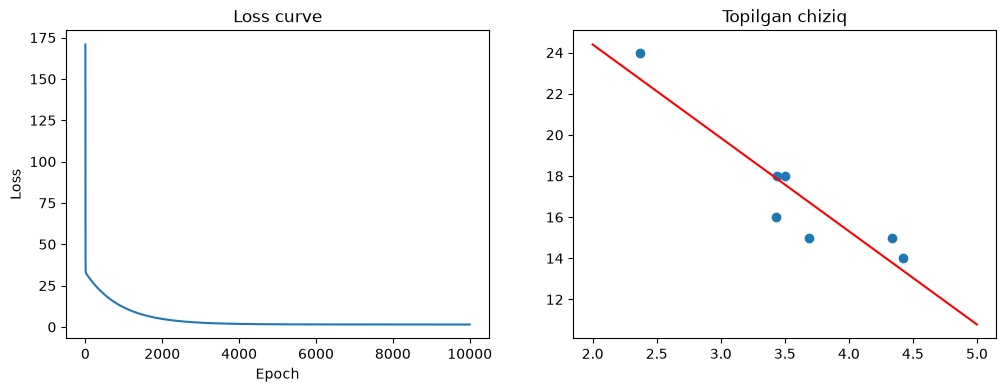

In [8]:
def train(x, y, learning_rate=0.01, epochs=10000):
    w, b = 0.0, 0.0
    losses = []
    for epoch in range(epochs):
        dw, db = gradients(x, y, w, b)
        w = w - learning_rate * dw
        b = b - learning_rate * db
        losses.append(mse_loss(y, predict(x, w, b)))
    return w, b, losses

w, b, losses = train(x, y)
print(f"w = {w:.3f}, b = {b:.3f}, loss = {losses[-1]:.3f}")

# Chapda loss curve, o'ngda topilgan chiziq
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(losses)
ax[0].set_title("Loss curve")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")

ax[1].scatter(x, y)
xs = np.linspace(2, 5, 100)
ax[1].plot(xs, predict(xs, w, b), color="red")
ax[1].set_title("Topilgan chiziq")
plt.show()

Mashq 4: Learning rate tajribasi

📖 Izoh: Bitta hyperparameter’ni o’zgartirib, uning ta’sirini ko’ramiz. Epochs soni hammasida bir xil, 2000 ta.

In [12]:
for lr in [0.001, 0.01, 0.05, 0.1]:
    w, b, losses = train(x, y, learning_rate=lr, epochs=2000)
    print(f"lr={lr:<6} -> w={w:.2f}, b={b:.2f}, loss={losses[-1]:.3f}")

lr=0.001  -> w=3.27, b=4.57, loss=26.746
lr=0.01   -> w=-1.71, b=22.99, loss=4.838
lr=0.05   -> w=-4.54, b=33.47, loss=1.470
lr=0.1    -> w=nan, b=nan, loss=nan


C:\Users\User\AppData\Local\Temp\ipykernel_9324\2487809468.py:5: RuntimeWarning: overflow encountered in square
  return np.mean((y_pred - y) ** 2)
C:\Users\User\AppData\Local\Temp\ipykernel_9324\2099443029.py:6: RuntimeWarning: invalid value encountered in scalar subtract
  w = w - learning_rate * dw
